# Deep Learning Spam Classifier (TF-IDF + Keras neural network)

**Task:** classify SMS messages as spam or ham with a multi-layer neural network using **Dropout**, **Batch Normalization** and **early stopping**, plot convergence, then score unseen messages with confidences.

**Data:** the SMS Spam Collection (Almeida & Hidalgo, UCI), 5,574 labelled English messages, downloaded from a public GitHub mirror on first run. It is a research dataset of 2000s-era UK/Singapore texts, so treat results as a demonstration, not a production spam filter.

**Leak-safe order:** drop duplicate texts → stratified train/validation/test split → fit TF-IDF on **train only** → train with the validation set driving early stopping → touch the test set once.

In [1]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import warnings; warnings.filterwarnings("ignore")
import urllib.request, json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers, callbacks
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, roc_curve, brier_score_loss)

SEED = 42
keras.utils.set_random_seed(SEED)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 150)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1794308103.399629     574 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794308104.639713     574 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Load, de-duplicate, split

In [2]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
PATH = "sms.tsv"
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)
df = pd.read_csv(PATH, sep="\t", header=None, names=["label", "text"])
assert set(df.label) == {"ham", "spam"}
n_raw = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)      # exact duplicates would straddle the split
print(f"{n_raw} rows -> {len(df)} after removing {n_raw - len(df)} duplicate texts")
df["y"] = (df.label == "spam").astype(int)
df["n_chars"] = df.text.str.len()
print(df.y.value_counts().rename({0: "ham", 1: "spam"}).to_string(), f"\nspam rate: {df.y.mean():.3f}")
df.groupby("label").n_chars.describe().round(1)

5572 rows -> 5169 after removing 403 duplicate texts
y
ham     4516
spam     653 
spam rate: 0.126


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.9,56.7,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


In [3]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(df.text, df.y, test_size=0.30, stratify=df.y, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print({k: (len(v), round(float(y.mean()), 3)) for k, v, y in [("train", X_tr, y_tr), ("val", X_val, y_val), ("test", X_te, y_te)]})

{'train': (3618, 0.126), 'val': (775, 0.126), 'test': (776, 0.126)}


## 2. Tokenise and vectorise with TF-IDF (fit on train only)
Unigrams and bigrams, lower-cased, sublinear term frequency, terms must appear in at least 2 training messages. The vocabulary and IDF weights come from the training split only.

In [4]:
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True, strip_accents="unicode")
A_tr = tfidf.fit_transform(X_tr).toarray().astype("float32")
A_val = tfidf.transform(X_val).toarray().astype("float32")
A_te = tfidf.transform(X_te).toarray().astype("float32")
print("feature matrix:", A_tr.shape, "| vocabulary size:", len(tfidf.vocabulary_))
top = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("most common terms:", list(top.index[:8]))

feature matrix: (3618, 5000) | vocabulary size: 5000
most common terms: ['to', 'you', 'the', 'and', 'in', 'is', 'me', 'for']


## 3. Reference baseline: logistic regression on the same features

In [5]:
base = LogisticRegression(C=10, max_iter=2000).fit(A_tr, y_tr)
p_base = base.predict_proba(A_te)[:, 1]
print(f"Baseline test ROC-AUC {roc_auc_score(y_te, p_base):.4f} | PR-AUC {average_precision_score(y_te, p_base):.4f}")

Baseline test ROC-AUC 0.9937 | PR-AUC 0.9778


## 4. Neural network
`Input → [Dense → BatchNorm → ReLU → Dropout] ×2 → sigmoid`. L2 weight decay on the first layer, Adam, binary cross-entropy. Callbacks: **EarlyStopping** on validation loss (restoring the best weights) and **ReduceLROnPlateau**.

In [6]:
def build_model(n_features, hidden=(256, 64), dropout=(0.5, 0.3), l2=1e-4, lr=1e-3):
    inp = keras.Input(shape=(n_features,), name="tfidf")
    x = inp
    for i, (h, d) in enumerate(zip(hidden, dropout)):
        x = layers.Dense(h, use_bias=False, kernel_regularizer=keras.regularizers.l2(l2) if i == 0 else None, name=f"dense_{i}")(x)
        x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Activation("relu", name=f"relu_{i}")(x)
        x = layers.Dropout(d, name=f"dropout_{i}")(x)
    out = layers.Dense(1, activation="sigmoid", name="spam_probability")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

model = build_model(A_tr.shape[1])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tfidf (InputLayer)              │ (None, 5000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 256)            │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_0 (Activation)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spam_probability (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297,729 (4.95 MB)

 Trainable params: 1,297,089 (4.95 MB)

 Non-trainable params: 640 (2.50 KB)

In [7]:
cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1)]
history = model.fit(A_tr, y_tr.values, validation_data=(A_val, y_val.values), epochs=60, batch_size=64,
                    callbacks=cbs, verbose=2)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nStopped after {len(history.history['loss'])} epochs; best validation loss at epoch {best_epoch} (weights restored).")

Epoch 1/60


57/57 - 2s - 38ms/step - accuracy: 0.8922 - auc: 0.9148 - loss: 0.3326 - val_accuracy: 0.8735 - val_auc: 0.9839 - val_loss: 0.5279 - learning_rate: 0.0010


Epoch 2/60


57/57 - 1s - 22ms/step - accuracy: 0.9854 - auc: 0.9928 - loss: 0.1222 - val_accuracy: 0.8735 - val_auc: 0.9906 - val_loss: 0.3563 - learning_rate: 0.0010


Epoch 3/60


57/57 - 1s - 20ms/step - accuracy: 0.9942 - auc: 0.9981 - loss: 0.0781 - val_accuracy: 0.8735 - val_auc: 0.9889 - val_loss: 0.2905 - learning_rate: 0.0010


... (49 outputs left out)

57/57 - 1s - 23ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0112 - val_accuracy: 0.9832 - val_auc: 0.9816 - val_loss: 0.0693 - learning_rate: 2.5000e-04


Epoch 27: early stopping


Restoring model weights from the end of the best epoch: 22.



Stopped after 27 epochs; best validation loss at epoch 22 (weights restored).


## 5. Convergence curves

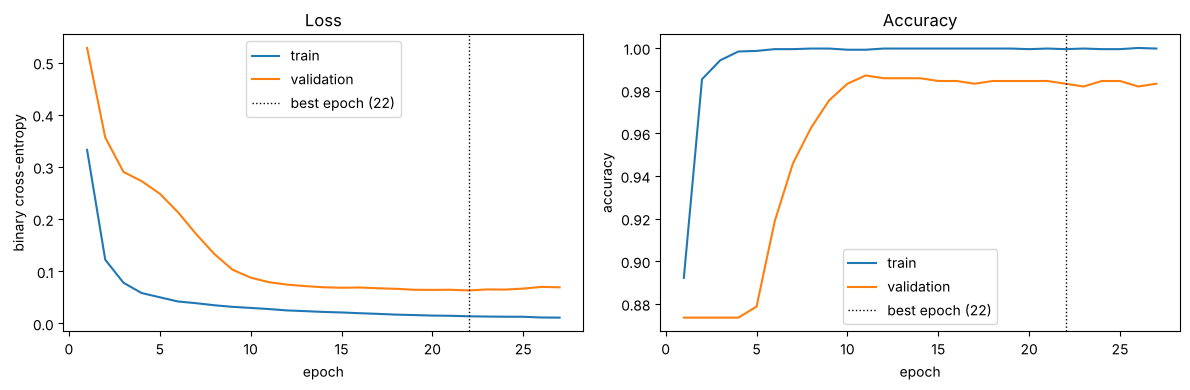

In [8]:
h = pd.DataFrame(history.history); ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, h.loss, label="train"); ax[0].plot(ep, h.val_loss, label="validation")
ax[0].set(xlabel="epoch", ylabel="binary cross-entropy", title="Loss")
ax[1].plot(ep, h.accuracy, label="train"); ax[1].plot(ep, h.val_accuracy, label="validation")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for a in ax: a.axvline(best_epoch, color="k", ls=":", lw=1, label=f"best epoch ({best_epoch})"); a.legend()
plt.tight_layout(); plt.show()

Training loss falls to near zero within a few epochs while validation loss plateaus around 0.063 and then starts to tick up: the early sign of overfitting that Dropout, weight decay and early stopping contain. The restored weights are from the validation-loss minimum.

One oddity worth understanding: validation accuracy sits at the majority-class rate (about 87%, i.e. "always ham") for the first few epochs even though training accuracy is already ~98%. That is Batch Normalization's running statistics lagging behind the fast-changing weights early in training (they are used at validation time, batch statistics at training time). It resolves by itself, and it is also why training/validation gaps in the first epochs should not be over-read.

## 6. One-time test evaluation

              precision    recall  f1-score   support

         ham      0.993     0.993     0.993       678
        spam      0.949     0.949     0.949        98

    accuracy                          0.987       776
   macro avg      0.971     0.971     0.971       776
weighted avg      0.987     0.987     0.987       776

Neural net  test ROC-AUC 0.9931 | PR-AUC 0.9789 | Brier 0.0106
Baseline LR test ROC-AUC 0.9937 | PR-AUC 0.9778 | Brier 0.0124


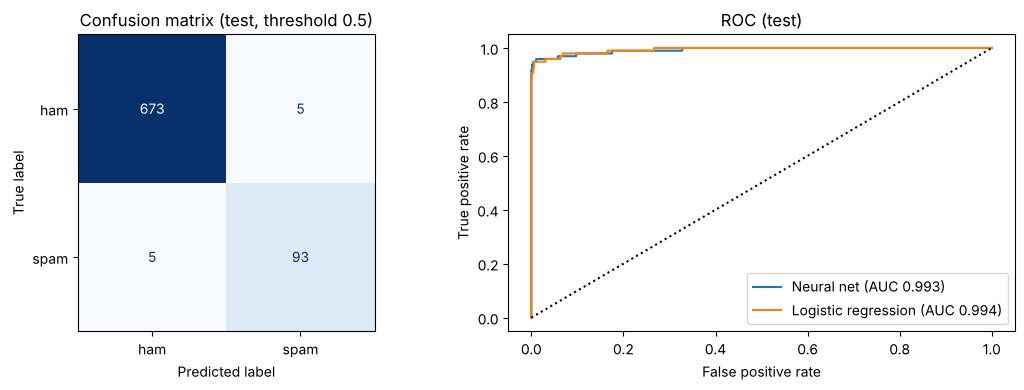

In [9]:
p_te = model.predict(A_te, verbose=0).ravel(); pred = (p_te >= 0.5).astype(int)
print(classification_report(y_te, pred, target_names=["ham", "spam"], digits=3))
print(f"Neural net  test ROC-AUC {roc_auc_score(y_te, p_te):.4f} | PR-AUC {average_precision_score(y_te, p_te):.4f} | Brier {brier_score_loss(y_te, p_te):.4f}")
print(f"Baseline LR test ROC-AUC {roc_auc_score(y_te, p_base):.4f} | PR-AUC {average_precision_score(y_te, p_base):.4f} | Brier {brier_score_loss(y_te, p_base):.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["ham", "spam"]).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title("Confusion matrix (test, threshold 0.5)")
for name, p in [("Neural net", p_te), ("Logistic regression", p_base)]:
    f, t, _ = roc_curve(y_te, p); ax[1].plot(f, t, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

The neural network and the logistic-regression baseline score almost identically here: on sparse TF-IDF features a linear model is already strong, so the network's value is mainly flexibility and a good test of the deep-learning workflow, not a large accuracy gain.

Spam filters have lopsided costs: blocking a real message (false positive) usually hurts more than letting spam through. If so, raise the threshold above 0.5 using the **validation** set, not the test set.

### Error analysis

In [10]:
err = pd.DataFrame({"text": X_te.values, "true": y_te.map({0: "ham", 1: "spam"}).values, "p_spam": p_te.round(3)})
err[pred != y_te.values].sort_values("p_spam")

,text,true,p_spam
538,ringtoneking 84484,spam,0.001
719,Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need you...,spam,0.003
2,Money i have won wining number 946 wot do i do next,spam,0.007
134,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50",spam,0.026
372,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,spam,0.450
300,I'm e person who's doing e sms survey...,ham,0.507
518,I'm at home. Please call,ham,0.555
555,Dont you have message offer,ham,0.794
575,Your daily text from me – a favour this time,ham,0.820
397,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PI...",ham,0.937


## 7. Inference on unseen messages

In [11]:
LABELS = {0: "ham", 1: "spam"}
def predict_texts(texts, threshold=0.5):
    """Return label, spam probability and confidence (probability of the predicted class)."""
    p = model.predict(tfidf.transform(texts).toarray().astype("float32"), verbose=0).ravel()
    lab = (p >= threshold).astype(int)
    return pd.DataFrame({"message": texts, "prediction": [LABELS[i] for i in lab], "p_spam": p.round(3),
                         "confidence": np.where(lab == 1, p, 1 - p).round(3)})

samples = [
    "WINNER!! You have been selected to receive a £900 prize reward. Call 09061701461 now to claim. Claim code KL341.",
    "Are we still meeting for lunch tomorrow? I can do 1pm.",
    "URGENT! Your mobile number has won a free 2000 cash award. Text WIN to 80082 to claim. T&Cs apply",
    "Hey, congratulations on the new job! Call me when you're free tonight.",
    "Free entry in our weekly competition! Text STOP to opt out. Reply YES to receive your free ringtone.",
    "Your OTP for login is 482913. Do not share it with anyone.",
    "Can you send me the notes from class? I missed the last lecture.",
    "Dear customer, your account has been suspended. Verify now at http://bit.ly/secure-check to avoid closure.",
    "ok",
]
results = predict_texts(samples); results

,message,prediction,p_spam,confidence
0,WINNER!! You have been selected to receive a £900 prize reward. Call 09061701461 now to claim. Claim code ...,spam,1.000,1.000
1,Are we still meeting for lunch tomorrow? I can do 1pm.,ham,0.004,0.996
2,URGENT! Your mobile number has won a free 2000 cash award. Text WIN to 80082 to claim. T&Cs apply,spam,1.000,1.000
3,"Hey, congratulations on the new job! Call me when you're free tonight.",ham,0.036,0.964
4,Free entry in our weekly competition! Text STOP to opt out. Reply YES to receive your free ringtone.,spam,1.000,1.000
5,Your OTP for login is 482913. Do not share it with anyone.,ham,0.007,0.993
6,Can you send me the notes from class? I missed the last lecture.,ham,0.000,1.000
7,"Dear customer, your account has been suspended. Verify now at http://bit.ly/secure-check to avoid closure.",ham,0.263,0.737
8,ok,ham,0.001,0.999


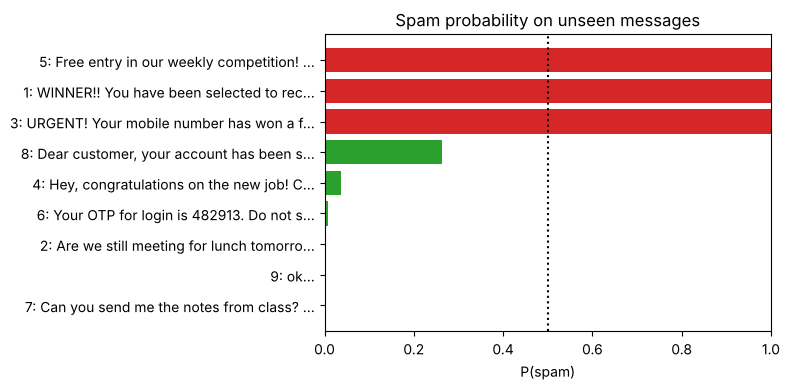

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
order = np.argsort(results.p_spam.values)
ax.barh([f"{i+1}: {samples[i][:38]}..." for i in order], results.p_spam.values[order],
        color=["tab:red" if v >= 0.5 else "tab:green" for v in results.p_spam.values[order]])
ax.axvline(0.5, color="k", ls=":"); ax.set(xlabel="P(spam)", xlim=(0, 1), title="Spam probability on unseen messages")
plt.tight_layout(); plt.show()

Read borderline scores with care: the model only knows the vocabulary and style of this older SMS corpus. Modern phishing, OTP messages, other languages and emoji are out of distribution, so a confident score there is not evidence of correctness. Pair it with human review for the middle band and retrain on current data.

## 8. Save and reload

In [13]:
model.save("spam_nn.keras"); joblib.dump(tfidf, "tfidf_vectorizer.joblib")
reloaded = keras.saving.load_model("spam_nn.keras")
chk = reloaded.predict(tfidf.transform(samples).toarray().astype("float32"), verbose=0).ravel()
assert np.allclose(chk, results.p_spam.values, atol=1e-3)
json.dump({"seed": SEED, "tensorflow": tf.__version__, "best_epoch": best_epoch,
           "test_roc_auc": float(roc_auc_score(y_te, p_te)), "threshold": 0.5}, open("spam_nn_card.json", "w"), indent=2)
print("Saved spam_nn.keras, tfidf_vectorizer.joblib, spam_nn_card.json; reload check passed.")

Saved spam_nn.keras, tfidf_vectorizer.joblib, spam_nn_card.json; reload check passed.
